# *Metode i primjena vještačke inteligencije, 2026/27*
# *Fovelum - Klasifikacija dijabetičke retinopatije*
# *Treća sedmica - Postavka okruženja, analiza podataka i izrada fiksnih train/val/test podjela*

In [ ]:
!pip -q install timm imagehash albumentations

## *Postavka okruženja i mount google drive-a*

In [ ]:
import os
import glob
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import imagehash
import zipfile
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

drive.mount('/content/drive')

# Definisanje glavnih putanja
BASE_DIR = '/content/drive/MyDrive/MPVI Fovelum'
ZIP_DIR = f'{BASE_DIR}/dataset zip'
OUT_DIR = f'{BASE_DIR}/rezultati'
os.makedirs(OUT_DIR, exist_ok=True)

# Mapa naziva klasa za dijabetičku retinopatiju
CLASS_NAMES = {
    0: '0 - No DR',
    1: '1 - Mild',
    2: '2 - Moderate',
    3: '3 - Severe',
    4: '4 - Proliferative DR'
}

print("Okruženje je uspješno postavljeno.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Okruženje je uspješno postavljeno.


## *Raspakivanje podataka na lokalni disk colaba*

In [ ]:
os.makedirs('/content/work/kaggle', exist_ok=True)
os.makedirs('/content/work/ddr', exist_ok=True)

if not os.listdir('/content/work/kaggle') or not os.listdir('/content/work/ddr'):
    # Automatsko traženje zip fajlova unutar BASE_DIR, a po potrebi i cijelog Drive-a
    kaggle_zips = glob.glob(f'{BASE_DIR}/**/archive.zip', recursive=True) or glob.glob('/content/drive/MyDrive/**/archive.zip', recursive=True)
    ddr_zips = glob.glob(f'{BASE_DIR}/**/DDR.zip', recursive=True) or glob.glob('/content/drive/MyDrive/**/DDR.zip', recursive=True)

    print("Pronađen Kaggle zip:", kaggle_zips)
    print("Pronađen DDR zip:   ", ddr_zips)

    if kaggle_zips and ddr_zips:
        with zipfile.ZipFile(kaggle_zips[0], 'r') as zf:
            zf.extractall('/content/work/kaggle')
        with zipfile.ZipFile(ddr_zips[0], 'r') as zf:
            zf.extractall('/content/work/ddr')
        print("\nArhive su uspješno raspakovane na lokalni disk.")
    else:
        print("\nGREŠKA: Neki od zip fajlova nije pronađen.")
else:
    print("Podaci su već raspakovani na lokalnom disku (/content/work).")

Podaci su već raspakovani na lokalnom disku (/content/work).


## *Kaggle APTOS 224x224*

### *Učitavanje i osnovni pregled (EDA)*

*pronalaženje CSV fajla i mapiranje putanje do svih slika*

In [ ]:
csv_path = glob.glob('/content/work/kaggle/**/train.csv', recursive=True)[0]
kaggle_df = pd.read_csv(csv_path)

all_kaggle_imgs = glob.glob('/content/work/kaggle/**/*.*', recursive=True)
all_kaggle_imgs = [p for p in all_kaggle_imgs if p.lower().endswith(('.png', '.jpg', '.jpeg'))]
id_to_path = {os.path.splitext(os.path.basename(p))[0]: p for p in all_kaggle_imgs}

kaggle_df['path'] = kaggle_df['id_code'].map(id_to_path)

print(f"Ukupno zapisa u Kaggle CSV-u: {len(kaggle_df)}")
print(f"Broj slika koje nedostaju na disku: {kaggle_df['path'].isnull().sum()}\n")

Ukupno zapisa u Kaggle CSV-u: 3662
Broj slika koje nedostaju na disku: 0



*izračun i prikaz distribucije klasa*

In [ ]:
counts = kaggle_df['diagnosis'].value_counts().sort_index()
percentages = (counts / len(kaggle_df) * 100).round(2)

summary_kaggle = pd.DataFrame({
    'Klasa': [CLASS_NAMES[i] for i in counts.index],
    'Broj slika': counts.values,
    'Udio (%)': percentages.values
})

print("Distribucija klasa (Kaggle APTOS 224x224):")
print(summary_kaggle.to_string(index=False))

Distribucija klasa (Kaggle APTOS 224x224):
               Klasa  Broj slika  Udio (%)
           0 - No DR        1805     49.29
            1 - Mild         370     10.10
        2 - Moderate         999     27.28
          3 - Severe         193      5.27
4 - Proliferative DR         295      8.06


*vizualizacija distribucije klasa*

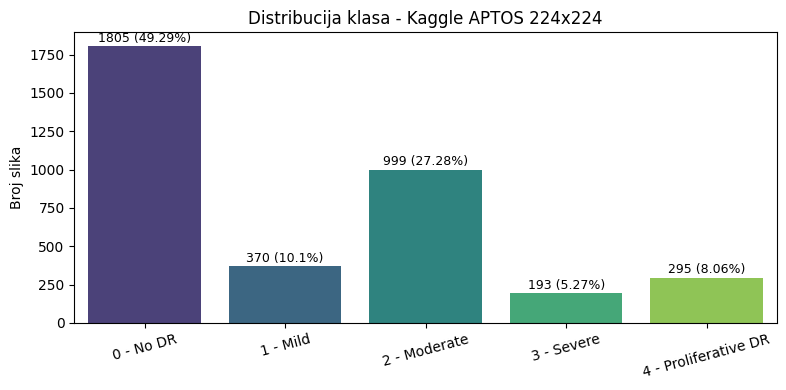

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(
    x=summary_kaggle['Klasa'],
    y=summary_kaggle['Broj slika'],
    hue=summary_kaggle['Klasa'],
    palette='viridis',
    legend=False
)
plt.title('Distribucija klasa - Kaggle APTOS 224x224')
plt.ylabel('Broj slika')
plt.xlabel('')
plt.xticks(rotation=15)
for i, v in enumerate(counts.values):
    plt.text(i, v + 30, f"{v} ({percentages.values[i]}%)", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### *Provjera kvaliteta slika i detekcija duplikata (MD5 + PHASH)*

In [ ]:
corrupted, sizes, modes, md5_list, phash_list = [], set(), set(), [], []

for _, row in tqdm(kaggle_df.iterrows(), total=len(kaggle_df), desc="Analiza Kaggle slika"):
    try:
        with open(row['path'], 'rb') as f:
            md5_list.append(hashlib.md5(f.read()).hexdigest())
        with Image.open(row['path']) as img:
            sizes.add(img.size)
            modes.add(img.mode)
            phash_list.append(imagehash.phash(img))
    except Exception as e:
        corrupted.append((row['id_code'], str(e)))
        md5_list.append(None)
        phash_list.append(None)

kaggle_df['md5'] = md5_list
kaggle_df['phash'] = phash_list

print(f"\nOštećenih slika: {len(corrupted)}")
print(f"Pronađene rezolucije: {sizes}")
print(f"Pronađeni color modovi: {modes}")

Analiza Kaggle slika:   0%|          | 0/3662 [00:00<?, ?it/s]


Oštećenih slika: 0
Pronađene rezolucije: {(224, 224)}
Pronađeni color modovi: {'RGB'}


*provjera egzaktnih MD5 duplikata*

In [ ]:
exact_dups = kaggle_df[kaggle_df.duplicated('md5', keep=False)]
print(f"Broj slika uključenih u egzaktne MD5 duplikate: {len(exact_dups)}")

Broj slika uključenih u egzaktne MD5 duplikate: 251


*provjera perceptualnih duplikata (Hamming distanca <= 2)*

In [ ]:
hashes = kaggle_df['phash'].values
near_dups = []
for i in range(len(hashes)):
    if hashes[i] is None:
        continue
    for j in range(i + 1, len(hashes)):
        if hashes[j] is None:
            continue
        dist = hashes[i] - hashes[j]
        if dist <= 2:
            near_dups.append((
                kaggle_df.loc[i, 'id_code'], kaggle_df.loc[j, 'id_code'],
                kaggle_df.loc[i, 'diagnosis'], kaggle_df.loc[j, 'diagnosis'],
                dist
            ))

dup_df = pd.DataFrame(near_dups, columns=['id_1', 'id_2', 'labela_1', 'labela_2', 'hamming_dist'])
print(f"Pronađeno perceptualnih parova (Hamming dist <= 2): {len(dup_df)}")
if len(dup_df) > 0:
    print("\nPrvih 10 perceptualnih parova:")
    print(dup_df.head(10).to_string(index=False))

Pronađeno perceptualnih parova (Hamming dist <= 2): 461

Prvih 10 perceptualnih parova:
        id_1         id_2  labela_1  labela_2  hamming_dist
00cb6555d108 ca25745942b0         1         1             0
012a242ac6ff 1f07dae3cadb         2         2             0
0161338f53cc cac40227d3b2         2         2             0
0243404e8a00 3b018e8b7303         4         3             0
0243404e8a00 3ddb86eb530e         4         2             0
026dcd9af143 98e8adcf085c         2         2             0
02da652c74b8 8acdf12f412a         0         0             2
02da652c74b8 999ad827ed35         0         0             2
034cb07a550f c8d2d32f7f29         4         4             0
04ac765f91a1 3044022c6969         1         1             0


*prikaz po 4 nasumična primjera za svaku klasu*

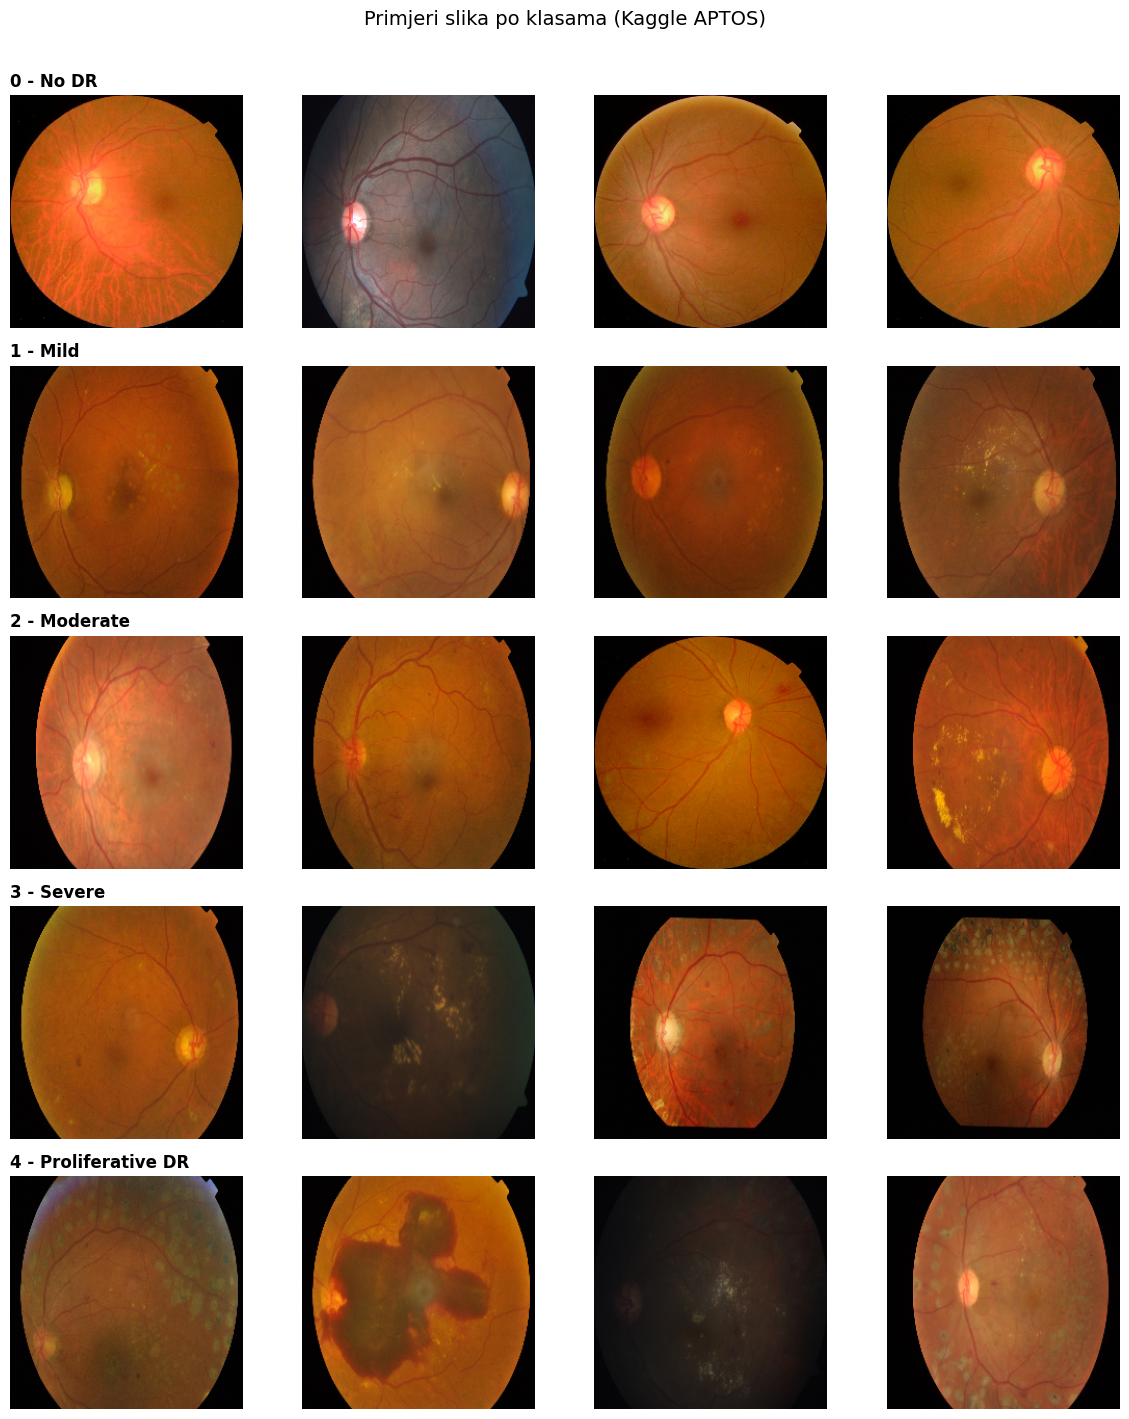

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(12, 14))
for cls in range(5):
    samples = kaggle_df[kaggle_df['diagnosis'] == cls].sample(4, random_state=42)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        with Image.open(row['path']) as img:
            axes[cls, col_idx].imshow(img)
        axes[cls, col_idx].axis('off')
        if col_idx == 0:
            axes[cls, col_idx].set_title(CLASS_NAMES[cls], loc='left', fontweight='bold')
plt.suptitle('Primjeri slika po klasama (Kaggle APTOS)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### *Čišćenje duplikata i stratificirana podjela (70/15/15)*

*uklanjanje MD5 grupa sa konfliktnim labelama i zadržavanje jednog primjerka kod istih*

In [ ]:
md5_label_counts = kaggle_df.groupby('md5')['diagnosis'].nunique()
conflicting_md5 = md5_label_counts[md5_label_counts > 1].index

print(f"MD5 grupe sa konfliktnim labelama (izbacuju se u potpunosti): {len(conflicting_md5)}")

kaggle_clean = kaggle_df[~kaggle_df['md5'].isin(conflicting_md5)].copy()
kaggle_clean = kaggle_clean.drop_duplicates(subset=['md5'], keep='first').reset_index(drop=True)
print(f"Broj slika nakon uklanjanja egzaktnih (MD5) duplikata: {len(kaggle_clean)}")

MD5 grupe sa konfliktnim labelama (izbacuju se u potpunosti): 30
Broj slika nakon uklanjanja egzaktnih (MD5) duplikata: 3504


*uklanjanje preostalih perceptualnih duplikata (Hamming distanca <= 2)*

In [ ]:
hashes = kaggle_clean['phash'].values
to_drop = set()
conflict_phash = 0
same_phash = 0

for i in range(len(hashes)):
    if i in to_drop:
        continue
    for j in range(i + 1, len(hashes)):
        if j in to_drop:
            continue
        if (hashes[i] - hashes[j]) <= 2:
            if kaggle_clean.loc[i, 'diagnosis'] == kaggle_clean.loc[j, 'diagnosis']:
                to_drop.add(j)
                same_phash += 1
            else:
                to_drop.add(i)
                to_drop.add(j)
                conflict_phash += 1

print(f"Dodatno izbačeno preko phash (ista labela: {same_phash}, konfliktne: {conflict_phash}): {len(to_drop)}")
kaggle_clean = kaggle_clean.drop(index=list(to_drop)).reset_index(drop=True)
print(f"Konačan broj čistih slika (Kaggle): {len(kaggle_clean)}\n")

Dodatno izbačeno preko phash (ista labela: 140, konfliktne: 35): 204
Konačan broj čistih slika (Kaggle): 3300



*stratificirana podjela 70% train / 15% val / 15% test sa fiksnim seedom 42*

In [ ]:
train_df, temp_df = train_test_split(
    kaggle_clean, test_size=0.30, stratify=kaggle_clean['diagnosis'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['diagnosis'], random_state=42
)

train_df['split'] = 'train'
val_df['split'] = 'val'
test_df['split'] = 'test'

kaggle_splits = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

print("Konačna stratificirana podjela po klasama (Kaggle):")
print(pd.crosstab(kaggle_splits['split'], kaggle_splits['diagnosis'], margins=True))

Konačna stratificirana podjela po klasama (Kaggle):
diagnosis     0    1    2    3    4   All
split                                    
test        248   49  135   24   39   495
train      1157  228  629  114  182  2310
val         248   49  134   25   39   495
All        1653  326  898  163  260  3300


*snimanje u CSV*

In [ ]:
kaggle_csv_out = f'{OUT_DIR}/kaggle_splits.csv'
kaggle_splits[['id_code', 'diagnosis', 'split']].to_csv(kaggle_csv_out, index=False)
print(f"\nPodjela je sačuvana u: {kaggle_csv_out}")


Podjela je sačuvana u: /content/drive/MyDrive/MPVI Fovelum/rezultati/kaggle_splits.csv


## *DDR Dataset*

### *Učitavanje predefinisane podjele i EDA*

In [ ]:
DDR_ROOT = '/content/work/ddr/DDR/DDR-dataset/DR_grading'

# Učitavanje originalnih train.txt, valid.txt i test.txt fajlova
dfs = []
for split_name, fname in [('train', 'train.txt'), ('val', 'valid.txt'), ('test', 'test.txt')]:
    fpath = os.path.join(DDR_ROOT, fname)
    tmp = pd.read_csv(fpath, sep=r'\s+', header=None, names=['filename', 'diagnosis'])
    tmp['split'] = split_name
    dfs.append(tmp)

ddr_df = pd.concat(dfs, ignore_index=True)

*mapiranje slika sa diska*

In [ ]:
all_ddr_imgs = glob.glob(f'{DDR_ROOT}/**/*.*', recursive=True)
all_ddr_imgs = [p for p in all_ddr_imgs if p.lower().endswith(('.jpg', '.jpeg', '.png'))]
fname_to_path = {os.path.basename(p): p for p in all_ddr_imgs}

ddr_df['path'] = ddr_df['filename'].map(fname_to_path)

print(f"Ukupno zapisa u DDR (train + valid + test): {len(ddr_df)}")
print(f"Broj slika koje nedostaju na disku: {ddr_df['path'].isnull().sum()}\n")

print("Distribucija klasa u DDR-u prije čišćenja (klasa 5 = Ungradable):")
print(pd.crosstab(ddr_df['split'], ddr_df['diagnosis'], margins=True))

Ukupno zapisa u DDR (train + valid + test): 13673
Broj slika koje nedostaju na disku: 0

Distribucija klasa u DDR-u prije čišćenja (klasa 5 = Ungradable):
diagnosis     0    1     2    3    4     5    All
split                                            
test       1880  189  1344   71  275   346   4105
train      3133  315  2238  118  456   575   6835
val        1253  126   895   47  182   230   2733
All        6266  630  4477  236  913  1151  13673


*prikaz distribucije prije uklanjanja klase 5*

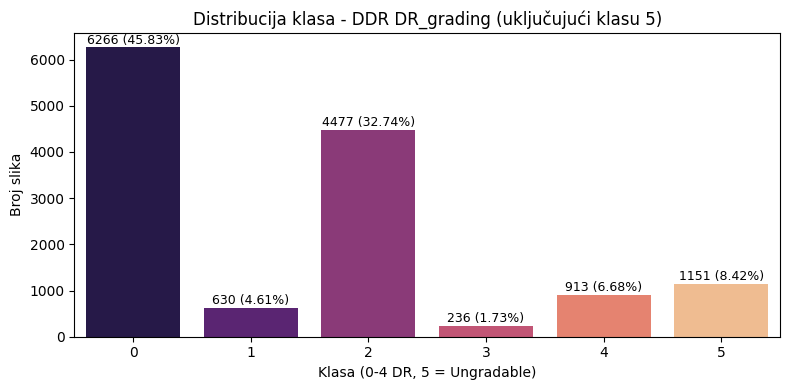

In [ ]:
counts_ddr = ddr_df['diagnosis'].value_counts().sort_index()
percentages_ddr = (counts_ddr / len(ddr_df) * 100).round(2)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=counts_ddr.index.astype(str),
    y=counts_ddr.values,
    hue=counts_ddr.index.astype(str),
    palette='magma',
    legend=False
)
plt.title('Distribucija klasa - DDR DR_grading (uključujući klasu 5)')
plt.xlabel('Klasa (0-4 DR, 5 = Ungradable)')
plt.ylabel('Broj slika')
for i, v in enumerate(counts_ddr.values):
    plt.text(i, v + 80, f"{v} ({percentages_ddr.values[i]}%)", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### *Uklanjanje neocjenjivih slika (klasa 5), provjera kvaliteta i duplikata*

*zadržavanje samo validnih klasa (0-4) radi usklađivanja sa Kaggle skupom*

In [ ]:
ddr_clean = ddr_df[ddr_df['diagnosis'].isin([0, 1, 2, 3, 4])].copy().reset_index(drop=True)
print(f"Broj slika nakon uklanjanja klase 5 (Ungradable): {len(ddr_clean)} (izbačeno {len(ddr_df) - len(ddr_clean)})\n")

Broj slika nakon uklanjanja klase 5 (Ungradable): 12522 (izbačeno 1151)



*provjera integriteta slika, rezolucija i MD5 hash-a*

In [ ]:
corrupted_ddr, sizes_ddr, modes_ddr, md5_ddr = [], [], set(), []

for _, row in tqdm(ddr_clean.iterrows(), total=len(ddr_clean), desc="Analiza DDR slika"):
    try:
        with open(row['path'], 'rb') as f:
            md5_ddr.append(hashlib.md5(f.read()).hexdigest())
        with Image.open(row['path']) as img:
            sizes_ddr.append(img.size)
            modes_ddr.add(img.mode)
    except Exception as e:
        corrupted_ddr.append((row['filename'], str(e)))
        md5_ddr.append(None)

ddr_clean['md5'] = md5_ddr

print(f"\nOštećenih slika: {len(corrupted_ddr)}")
print(f"Pronađeni color modovi: {modes_ddr}")
print(f"Broj različitih rezolucija: {len(set(sizes_ddr))}")
print(f"Top 5 najčešćih rezolucija: {pd.Series(sizes_ddr).value_counts().head(5).to_dict()}")

Analiza DDR slika:   0%|          | 0/12522 [00:00<?, ?it/s]


Oštećenih slika: 0
Pronađeni color modovi: {'RGB'}
Broj različitih rezolucija: 130
Top 5 najčešćih rezolucija: {(2592, 1728): 2155, (2736, 1824): 2119, (2048, 1536): 1427, (2304, 1728): 981, (3888, 2592): 664}


*provjera i čišćenje MD5 duplikata (sa prioritetom train - val - test zbog data leakage-a)*

In [ ]:
exact_dups_ddr = ddr_clean[ddr_clean.duplicated('md5', keep=False)]
print(f"Broj slika uključenih u egzaktne MD5 duplikate: {len(exact_dups_ddr)}")

if len(exact_dups_ddr) > 0:
    conflicting_ddr = ddr_clean.groupby('md5')['diagnosis'].nunique()
    conflicting_ddr = conflicting_ddr[conflicting_ddr > 1].index
    ddr_clean = ddr_clean[~ddr_clean['md5'].isin(conflicting_ddr)].copy()

    split_order = {'train': 0, 'val': 1, 'test': 2}
    ddr_clean['split_rank'] = ddr_clean['split'].map(split_order)
    ddr_clean = (
        ddr_clean.sort_values('split_rank')
        .drop_duplicates(subset=['md5'], keep='first')
        .drop(columns=['split_rank'])
        .reset_index(drop=True)
    )
    print(f"Broj slika nakon uklanjanja MD5 duplikata/konflikata: {len(ddr_clean)}")

print("\nKonačna podjela po klasama (DDR, klase 0-4):")
print(pd.crosstab(ddr_clean['split'], ddr_clean['diagnosis'], margins=True))

Broj slika uključenih u egzaktne MD5 duplikate: 197
Broj slika nakon uklanjanja MD5 duplikata/konflikata: 12422

Konačna podjela po klasama (DDR, klase 0-4):
diagnosis     0    1     2    3    4    All
split                                      
test       1843  189  1344   71  275   3722
train      3089  315  2238  118  456   6216
val        1234  126   895   47  182   2484
All        6166  630  4477  236  913  12422


*prikaz po 4 nasumična primjera za svaku klasu*

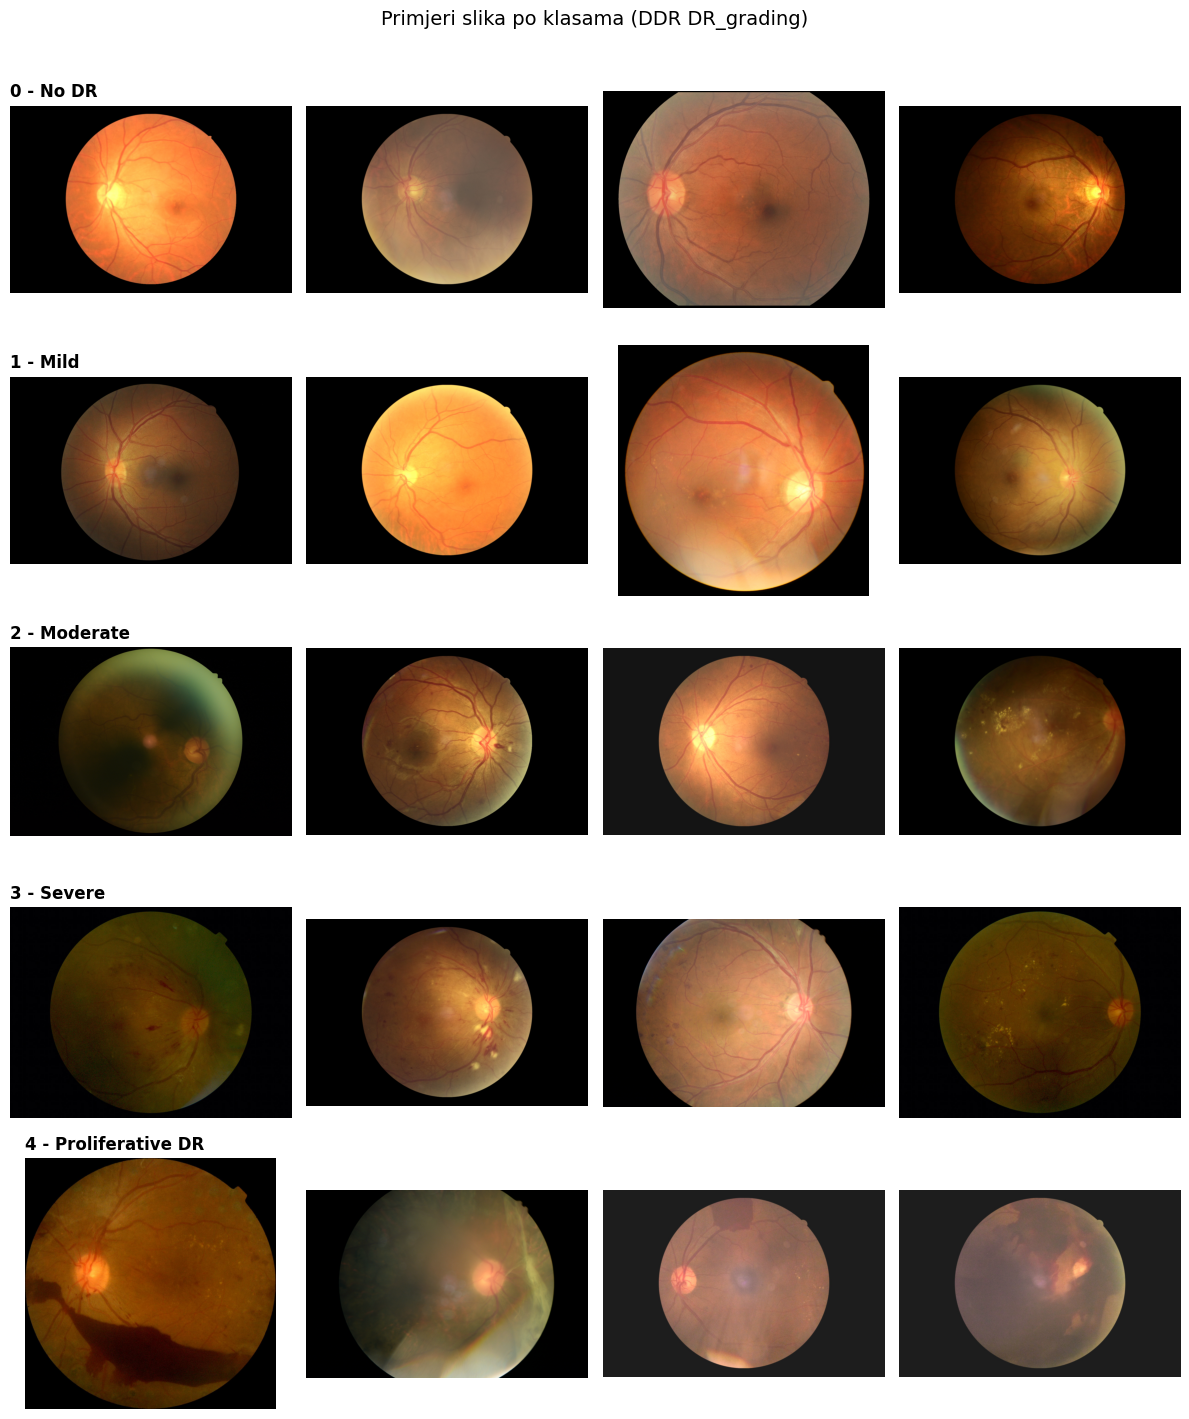

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(12, 14))
for cls in range(5):
    samples = ddr_clean[ddr_clean['diagnosis'] == cls].sample(4, random_state=42)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        with Image.open(row['path']) as img:
            axes[cls, col_idx].imshow(img)
        axes[cls, col_idx].axis('off')
        if col_idx == 0:
            axes[cls, col_idx].set_title(CLASS_NAMES[cls], loc='left', fontweight='bold')
plt.suptitle('Primjeri slika po klasama (DDR DR_grading)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

*snimanje u CSV*

In [ ]:
ddr_csv_out = f'{OUT_DIR}/ddr_splits.csv'
ddr_clean[['filename', 'diagnosis', 'split']].to_csv(ddr_csv_out, index=False)
print(f"\nPodjela je sačuvana u: {ddr_csv_out}")


Podjela je sačuvana u: /content/drive/MyDrive/MPVI Fovelum/rezultati/ddr_splits.csv


## *Uporedni pregled finalnih skupova, cross-dataset provjera i težinske klase*

In [ ]:
k_df = pd.read_csv(f'{OUT_DIR}/kaggle_splits.csv')
d_df = pd.read_csv(f'{OUT_DIR}/ddr_splits.csv')

*1. Provjera preklapanja slika između Kaggle i DDR skupa preko MD5 hash-a*

In [ ]:
overlap_md5 = set(kaggle_clean['md5']).intersection(set(ddr_clean['md5']))
print(f"Broj identičnih slika (MD5) između Kaggle i DDR skupa: {len(overlap_md5)}\n")

Broj identičnih slika (MD5) između Kaggle i DDR skupa: 0



*2. Uporedna tabela broja slika po splitovima i klasama*

In [ ]:
comp = pd.DataFrame({
    'Kaggle_Train': k_df[k_df['split'] == 'train']['diagnosis'].value_counts().sort_index(),
    'Kaggle_Val':   k_df[k_df['split'] == 'val']['diagnosis'].value_counts().sort_index(),
    'Kaggle_Test':  k_df[k_df['split'] == 'test']['diagnosis'].value_counts().sort_index(),
    'Kaggle_Total': k_df['diagnosis'].value_counts().sort_index(),
    'DDR_Train':    d_df[d_df['split'] == 'train']['diagnosis'].value_counts().sort_index(),
    'DDR_Val':      d_df[d_df['split'] == 'val']['diagnosis'].value_counts().sort_index(),
    'DDR_Test':     d_df[d_df['split'] == 'test']['diagnosis'].value_counts().sort_index(),
    'DDR_Total':    d_df['diagnosis'].value_counts().sort_index(),
})
comp.index.name = 'Klasa'
comp.loc['Ukupno'] = comp.sum()

print("Uporedni pregled čistih skupova podataka:")
print(comp)

Uporedni pregled čistih skupova podataka:
        Kaggle_Train  Kaggle_Val  Kaggle_Test  Kaggle_Total  DDR_Train  \
Klasa                                                                    
0               1157         248          248          1653       3089   
1                228          49           49           326        315   
2                629         134          135           898       2238   
3                114          25           24           163        118   
4                182          39           39           260        456   
Ukupno          2310         495          495          3300       6216   

        DDR_Val  DDR_Test  DDR_Total  
Klasa                                 
0          1234      1843       6166  
1           126       189        630  
2           895      1344       4477  
3            47        71        236  
4           182       275        913  
Ukupno     2484      3722      12422  


*3. Izračun balansiranih težina klasa na train splitu (za CrossEntropyLoss / Sampler)*

In [ ]:
classes = np.array([0, 1, 2, 3, 4])
k_weights = compute_class_weight('balanced', classes=classes, y=k_df[k_df['split'] == 'train']['diagnosis'])
d_weights = compute_class_weight('balanced', classes=classes, y=d_df[d_df['split'] == 'train']['diagnosis'])

weights_df = pd.DataFrame({
    'Klasa': [CLASS_NAMES[i] for i in classes],
    'Kaggle_Weight': np.round(k_weights, 4),
    'DDR_Weight': np.round(d_weights, 4)
})

print("\nPreporučene balansirane težine klasa (izračunate na train splitu):")
print(weights_df.to_string(index=False))


Preporučene balansirane težine klasa (izračunate na train splitu):
               Klasa  Kaggle_Weight  DDR_Weight
           0 - No DR         0.3993      0.4025
            1 - Mild         2.0263      3.9467
        2 - Moderate         0.7345      0.5555
          3 - Severe         4.0526     10.5356
4 - Proliferative DR         2.5385      2.7263


## *Analiza piksela (RGB Mean, STD) i provjera crnih rubova (train skup)*

*računa RGB mean/std i prosječan udio tamnih (crnih) piksela na uzorku*

In [ ]:
def analyze_image_stats(df_subset, sample_size=300, black_thresh=10):
    sample_df = df_subset.sample(min(sample_size, len(df_subset)), random_state=42)
    means, stds, black_ratios = [], [], []

    for path in tqdm(sample_df['path'], desc="Analiza piksela"):
        with Image.open(path) as img:
            # Smanjujemo sliku na 224x224 radi brzog izračuna (posebno bitno za velike DDR slike)
            img_small = img.convert('RGB').resize((224, 224))
            arr = np.asarray(img_small, dtype=np.float32) / 255.0
            means.append(arr.mean(axis=(0, 1)))
            stds.append(arr.std(axis=(0, 1)))
            is_black = np.all(arr < (black_thresh / 255.0), axis=-1)
            black_ratios.append(is_black.mean() * 100.0)

    return np.mean(means, axis=0), np.mean(stds, axis=0), np.mean(black_ratios)

*spajamo putanje iz čistih dataframe-ova na train splitove*

In [ ]:
k_train = kaggle_clean.merge(k_df[k_df['split'] == 'train'][['id_code']], on='id_code')
d_train = ddr_clean.merge(d_df[d_df['split'] == 'train'][['filename']], on='filename')

k_mean, k_std, k_black = analyze_image_stats(k_train)
d_mean, d_std, d_black = analyze_image_stats(d_train)

stats_df = pd.DataFrame({
    'Skup (Train uzorak)': ['Kaggle APTOS', 'DDR DR_grading', 'ImageNet (referenca)'],
    'RGB Mean': [[round(float(x), 4) for x in k_mean], [round(float(x), 4) for x in d_mean], [0.485, 0.456, 0.406]],
    'RGB Std':  [[round(float(x), 4) for x in k_std],  [round(float(x), 4) for x in d_std],  [0.229, 0.224, 0.225]],
    'Crni rubovi (%)': [round(float(k_black), 2), round(float(d_black), 2), '-']
})

print("Statistika piksela i crnih margina na trening skupu:")
print(stats_df.to_string(index=False))

Analiza piksela:   0%|          | 0/300 [00:00<?, ?it/s]

Analiza piksela:   0%|          | 0/300 [00:00<?, ?it/s]

Statistika piksela i crnih margina na trening skupu:
 Skup (Train uzorak)                 RGB Mean                 RGB Std Crni rubovi (%)
        Kaggle APTOS   [0.416, 0.224, 0.0762] [0.2388, 0.133, 0.0507]           22.69
      DDR DR_grading [0.3248, 0.1974, 0.0995] [0.277, 0.1759, 0.0927]           39.07
ImageNet (referenca)    [0.485, 0.456, 0.406]   [0.229, 0.224, 0.225]               -


*kreiranje grafikona sa 2 panela*

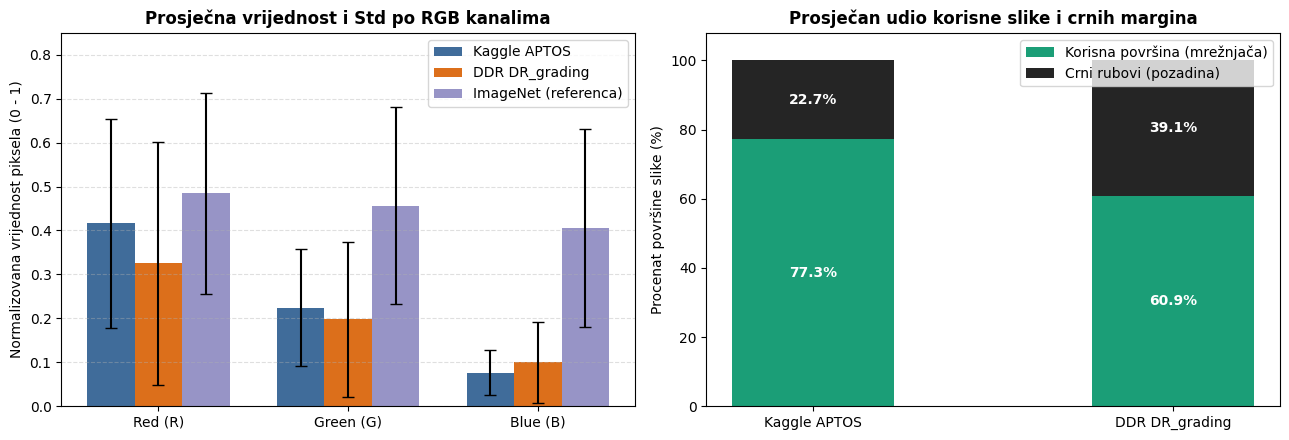

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Poređenje RGB Mean i Std po kanalima
channels = ['Red (R)', 'Green (G)', 'Blue (B)']
x = np.arange(len(channels))
width = 0.25

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

axes[0].bar(x - width, k_mean, width, yerr=k_std, capsize=4, label='Kaggle APTOS', color='#2b5c8f', alpha=0.9)
axes[0].bar(x,         d_mean, width, yerr=d_std, capsize=4, label='DDR DR_grading', color='#d95f02', alpha=0.9)
axes[0].bar(x + width, imagenet_mean, width, yerr=imagenet_std, capsize=4, label='ImageNet (referenca)', color='#7570b3', alpha=0.75)

axes[0].set_title('Prosječna vrijednost i Std po RGB kanalima', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(channels)
axes[0].set_ylabel('Normalizovana vrijednost piksela (0 - 1)')
axes[0].set_ylim(0, 0.85)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].legend()

# Panel 2: Udio crnih margina naspram korisne površine slike
datasets = ['Kaggle APTOS', 'DDR DR_grading']
black_vals = [float(k_black), float(d_black)]
retina_vals = [100.0 - float(k_black), 100.0 - float(d_black)]

axes[1].bar(datasets, retina_vals, label='Korisna površina (mrežnjača)', color='#1b9e77', width=0.45)
axes[1].bar(datasets, black_vals, bottom=retina_vals, label='Crni rubovi (pozadina)', color='#252525', width=0.45)

for i, (r_val, b_val) in enumerate(zip(retina_vals, black_vals)):
    axes[1].text(i, r_val / 2, f"{r_val:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    axes[1].text(i, r_val + b_val / 2, f"{b_val:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=10)

axes[1].set_title('Prosječan udio korisne slike i crnih margina', fontweight='bold')
axes[1].set_ylabel('Procenat površine slike (%)')
axes[1].set_ylim(0, 108)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

*Zaključak analize piksela i crnih margina*

1. **Distribucija po kanalima boje (RGB):** Slike očnog dna u oba skupa imaju izraženu dominaciju crvenog kanala (`Mean: 0.416` za Kaggle i `0.325` za DDR), umjeren zeleni kanal i vrlo nizak intenzitet i kontrast u plavom kanalu (`Std: 0.051` i `0.093`), koji uglavnom nosi šum. Vrijednosti značajno odstupaju od ImageNet standarda, što je važno uzeti u obzir prilikom normalizacije ulaznih tenzora.

2. **Uticaj crnih rubova (pozadine):** DDR slike u prosjeku sadrže **39.1% crnih margina** oko mrežnjače, u poređenju sa **22.7%** kod Kaggle skupa (koji je već djelimično isječen). Zbog većeg udjela crne pozadine u DDR-u, u narednim fazama preprocessing-a preporučuje se automatsko isijecanje crnog okvira (*auto-cropping*) prije promjene rezolucije na `224×224`, kako bi skala i veličina mrežnjače bile ujednačene između oba skupa.

## *Pytorch dataset, DATALOADER i sanity check (provjera BATCH-a)*

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

*univerzalni Dataset za Kaggle APTOS i DDR skupove podataka.*

In [ ]:
class RetinopathyDataset(Dataset):
    def __init__(self, df, id_col, path_map, transform=None):
        self.df = df.reset_index(drop=True)
        self.id_col = id_col
        self.path_map = path_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.path_map[row[self.id_col]]
        label = int(row['diagnosis'])

        with Image.open(img_path) as img:
            image = np.array(img.convert('RGB'))

        if self.transform is not None:
            augmented = self.transform(image=image)
            image = augmented['image']

        return image, torch.tensor(label, dtype=torch.long)

*definiše transformacije za trening i validaciju/test.*

In [ ]:
def get_transforms(img_size=224):
    train_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    val_tf = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    return train_tf, val_tf

*kreira train, val i test DataLoader objekte iz zadatog splits CSV-a.*

In [ ]:
def create_dataloaders(splits_df, id_col, path_map, batch_size=32, num_workers=2):
    train_tf, val_tf = get_transforms(img_size=224)

    train_ds = RetinopathyDataset(splits_df[splits_df['split'] == 'train'], id_col, path_map, train_tf)
    val_ds   = RetinopathyDataset(splits_df[splits_df['split'] == 'val'],   id_col, path_map, val_tf)
    test_ds  = RetinopathyDataset(splits_df[splits_df['split'] == 'test'],  id_col, path_map, val_tf)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

    return train_loader, val_loader, test_loader

*Sanity check: testiranje učitavanja jednog batch-a za oba skupa*

In [ ]:
k_train_loader, k_val_loader, k_test_loader = create_dataloaders(k_df, 'id_code', id_to_path, batch_size=16)
d_train_loader, d_val_loader, d_test_loader = create_dataloaders(d_df, 'filename', fname_to_path, batch_size=16)

k_imgs, k_labels = next(iter(k_train_loader))
d_imgs, d_labels = next(iter(d_train_loader))

print("Sanity check za DataLoader (batch_size=16):")
print(f"Kaggle batch - oblik tenzora: {tuple(k_imgs.shape)}, tip: {k_imgs.dtype}, labele: {k_labels.tolist()}")
print(f"DDR batch    - oblik tenzora: {tuple(d_imgs.shape)}, tip: {d_imgs.dtype}, labele: {d_labels.tolist()}")

Sanity check za DataLoader (batch_size=16):
Kaggle batch - oblik tenzora: (16, 3, 224, 224), tip: torch.float32, labele: [0, 1, 0, 0, 0, 3, 0, 2, 1, 1, 0, 4, 2, 0, 2, 2]
DDR batch    - oblik tenzora: (16, 3, 224, 224), tip: torch.float32, labele: [0, 2, 0, 1, 0, 2, 2, 0, 4, 2, 3, 0, 0, 2, 0, 2]


*vizuelni prikaz prvih 8 slika iz Kaggle i DDR trening batch-a (nakon augmentacija)*

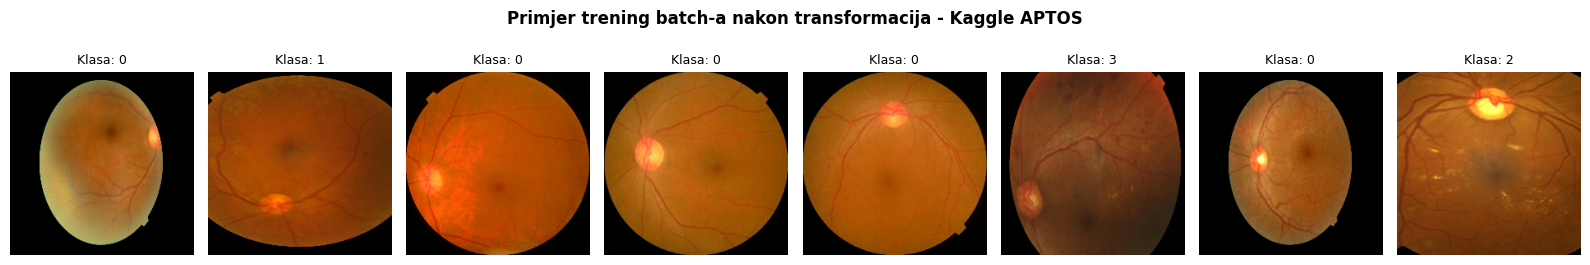

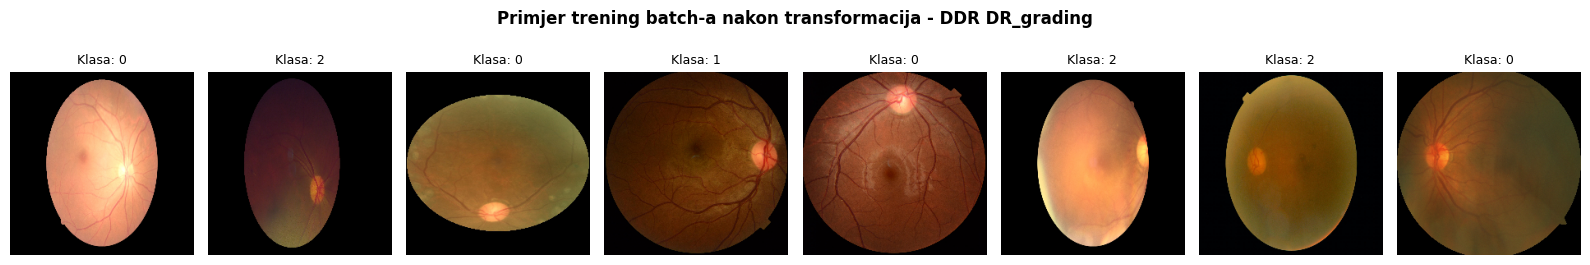

In [ ]:
def show_batch_samples(images, labels, title):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
    for i in range(8):
        # Denormalizacija tenzora [C, H, W] u [H, W, C] za prikaz
        img = images[i].permute(1, 2, 0).numpy()
        img = np.clip((img * std) + mean, 0, 1)
        axes[i].imshow(img)
        axes[i].set_title(f"Klasa: {labels[i].item()}", fontsize=9)
        axes[i].axis('off')
    plt.suptitle(title, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

show_batch_samples(k_imgs, k_labels, "Primjer trening batch-a nakon transformacija - Kaggle APTOS")
show_batch_samples(d_imgs, d_labels, "Primjer trening batch-a nakon transformacija - DDR DR_grading")

*Provjera DataLoader-a i finalni zaključak*

* **Ujednačene dimenzije tenzora `(16, 3, 224, 224)`:** Iako slike u DDR skupu imaju različite i znatno veće originalne rezolucije u odnosu na Kaggle (`224×224`), `RetinopathyDataset` i transformacije uspješno svode oba skupa na identičan format ulaznih tenzora (`[batch_size, kanali, visina, širina]`), što omogućava korištenje iste arhitekture modela za oba skupa.

* **Tip podataka i normalizacija (`torch.float32`):** Slike su ispravno konvertovane u PyTorch tenzore standardnog 32-bitnog formata sa normalizovanim vrijednostima piksela, spremne za GPU trening.
* **Nasumično miješanje (`shuffle=True`):** Raspored labela unutar jednog batch-a (npr. `[0, 1, 0, 0, 0, 3, ...]`) potvrđuje da `DataLoader` nasumično miješa uzorke na trening skupu, dok se na validacionom i testnom skupu zadržava deterministički redoslijed (`shuffle=False`).

***Rezultat treće sedmice:*** Svi podaci su očišćeni od duplikata i neocjenjivih uzoraka, fiksne podjele su pohranjene u `kaggle_splits.csv` i `ddr_splits.csv`, a `Dataset` i `DataLoader` klase su verificirane i spremne za prebacivanje u modularni kod (`src/dataset.py`) za trening modela.